<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (SOLUTION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor’s support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


### **Quick self-check — reference answers**

- **k-means vs. hierarchical clustering:** k-means requires the number of clusters *k* to be fixed in advance, and searches for the partition that minimizes within-cluster variance for that fixed *k*. Hierarchical (agglomerative) clustering builds a full nested sequence of partitions (from *N* singleton clusters down to 1), visualized as a dendrogram; the number of clusters is chosen *afterwards* by cutting the dendrogram at a chosen height/distance, without re-running the algorithm.
- **Why k-means can fail:** k-means assigns points to the nearest centroid using Euclidean distance, which implicitly assumes clusters are roughly spherical, similarly sized, and similarly dense. On elongated/anisotropic clusters, clusters with very different variances, or very unevenly sized clusters, this assumption breaks down and k-means can split or merge clusters incorrectly (as shown in the S3 notebook's "different shapes" example).
- **What BIC is used for:** in a Gaussian Mixture Model, adding more components always improves the likelihood of the training data, so likelihood alone cannot be used to choose the number of components. BIC adds a penalty term proportional to the number of parameters (and log of the sample size), so it rewards a better fit but penalizes unnecessary complexity — the number of components that minimizes BIC is taken as the "best" trade-off between fit and simplicity.

---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`) and drop rows with missing values (`.dropna()`).

b) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to these 4 numeric columns. Store the resulting labels in a variable `kmeans_labels`.

c) Add the cluster labels as a new column in your dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1.

d) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

e) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any?

### ✅ Solution

(342, 7)


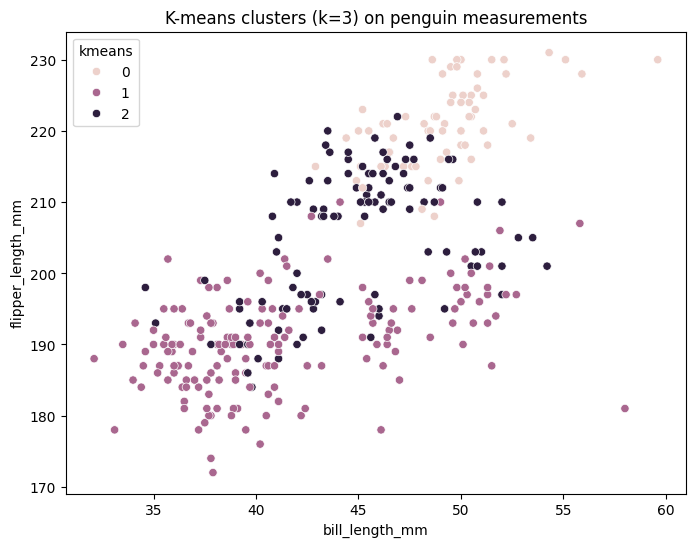

Confusion matrix (rows=true species, columns=k-means cluster):
[[  0 116  35]
 [  0  53  15]
 [ 68   1  54]]
Adjusted Rand Score: 0.33071304721058914


In [5]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder

penguins = sns.load_dataset('penguins')

# a) keep numeric columns and drop missing values
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
penguins_clean = penguins.dropna(subset=num_cols + ['species']).copy()
print(penguins_clean.shape)

# b) apply KMeans with n_clusters=3
kmeans_labels = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(penguins_clean[num_cols])

# c) add labels to the dataframe and plot
penguins_clean['kmeans'] = kmeans_labels

fig = plt.figure(figsize=(8, 6))
ax = sns.scatterplot(x='bill_length_mm', y='flipper_length_mm', hue='kmeans', data=penguins_clean)
ax.set_title('K-means clusters (k=3) on penguin measurements')
plt.show()

# d) confusion matrix and adjusted Rand score vs real 'species'
# Convert string species labels to numerical labels for confusion_matrix and adjusted_rand_score
le = LabelEncoder()
species_numerical = le.fit_transform(penguins_clean['species'])

cm = confusion_matrix(species_numerical, kmeans_labels)
print("Confusion matrix (rows=true species, columns=k-means cluster):")
print(cm)

ars = adjusted_rand_score(species_numerical, kmeans_labels)
print("Adjusted Rand Score:", ars)

**e) Interpretation (for the instructor to discuss in class):**

K-means recovers the 3 species reasonably well but not perfectly (ARI is typically around 0.6–0.7, well above chance but far from 1). The confusion matrix usually shows that Adelie and Chinstrap penguins are the two species most often confused with each other, since they overlap more in bill and body-size measurements, while Gentoo tends to form a cleaner, separate cluster because it is noticeably larger and has different bill proportions. This is a good moment in class to connect back to the S3 discussion of k-means' spherical-cluster assumption: species with more overlapping, less spherical feature distributions are exactly the case where k-means struggles most.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

b) Apply **Agglomerative Clustering** with `n_clusters=2` to `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

c) Also apply **k-means** with `n_clusters=2` to the same data `X`.

d) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays.)

e) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

### ✅ Solution

5.656854249492381
5.656854249492381


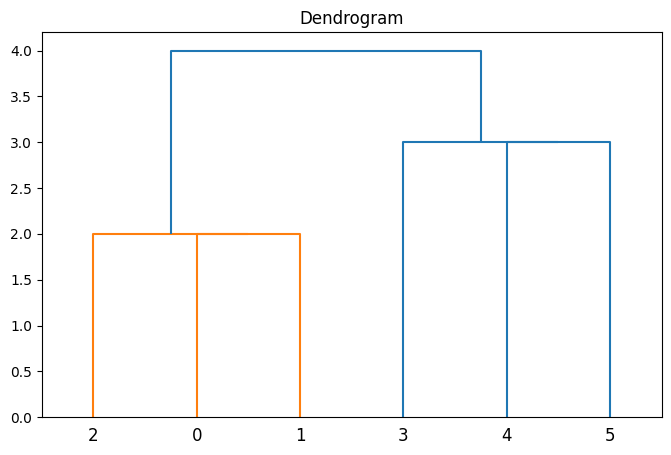

Agglomerative: [1 1 1 0 0 0]
K-means:       [0 0 0 1 1 1]
Agglomerative sizes: {np.int64(1): 3, np.int64(0): 3}
K-means sizes:       {np.int32(0): 3, np.int32(1): 3}


In [6]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) plain-Python euclidean_distance function using a for loop
def euclidean_distance(p1, p2):
    total = 0.0
    for i in range(len(p1)):
        total += (p1[i] - p2[i]) ** 2
    return total ** 0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# b) agglomerative clustering + dendrogram
agglo_labels = AgglomerativeClustering(n_clusters=2).fit_predict(X)

Z = linkage(X)
plt.figure(figsize=(8, 5))
dendrogram(Z)
plt.title('Dendrogram')
plt.show()

# c) k-means clustering with n_clusters=2
kmeans_labels = KMeans(n_clusters=2, random_state=0, n_init=10).fit_predict(X)

# d) compare both label arrays
print("Agglomerative:", agglo_labels)
print("K-means:      ", kmeans_labels)

# e) cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
    return counts

print("Agglomerative sizes:", cluster_sizes(agglo_labels))
print("K-means sizes:      ", cluster_sizes(kmeans_labels))


**Discussion note for class:** on this small, well-separated toy dataset both methods should produce the same partition (same two groups of 3 points each), even though the raw label *numbers* (0/1) may be swapped between the two methods — worth pointing out explicitly, since students often mistakenly conclude the methods "disagree" just because the label numbering differs. This is a good moment to segue into discussing cases (from the S3 notebook's synthetic-blob examples) where the two methods *do* genuinely disagree.

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`.

b) As done in the S3 notebook, fit a **Gaussian Mixture Model** for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

c) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

d) Add `gmm_labels` as a new column to `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1.

e) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye?

### ✅ Solution

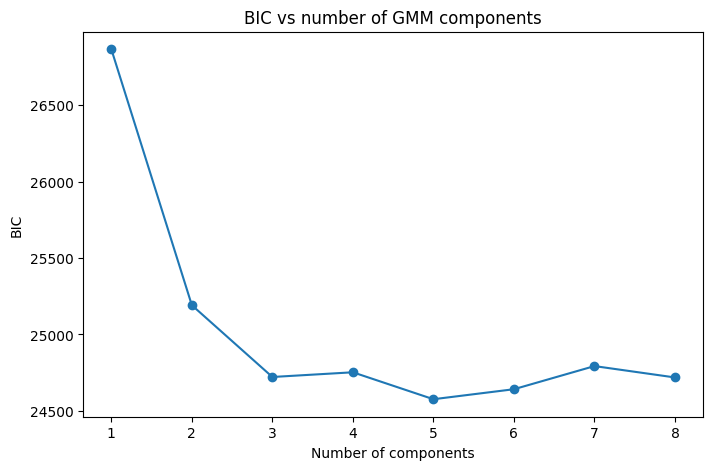

Best number of components (min BIC): 5


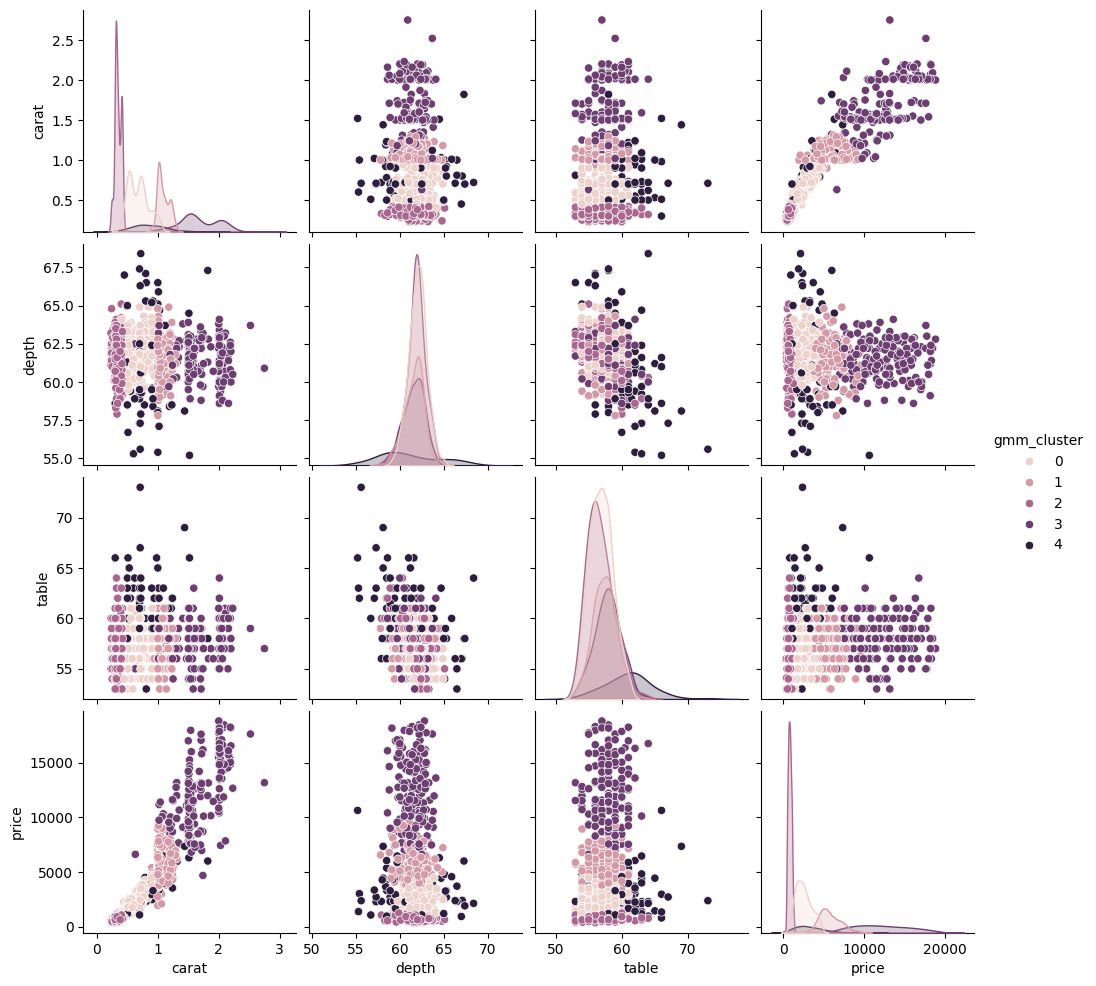

In [7]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn import mixture

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) select numeric columns into diamonds_num
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']].copy()

# b) fit GMM for n_components = 1..8, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)
for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, covariance_type='full', random_state=0).fit(diamonds_num)
    bic.append(gmm.bic(diamonds_num))

plt.figure(figsize=(8, 5))
plt.plot(list(n_components_range), bic, marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.title('BIC vs number of GMM components')
plt.show()

# c) find the number of components that minimizes BIC and fit the final GMM
best_n = list(n_components_range)[np.argmin(bic)]
print("Best number of components (min BIC):", best_n)

gmm_final = mixture.GaussianMixture(n_components=best_n, covariance_type='full', random_state=0).fit(diamonds_num)
gmm_labels = gmm_final.predict(diamonds_num)

# d) add gmm_labels to diamonds_num and create a pairplot colored by gmm_labels
diamonds_num['gmm_cluster'] = gmm_labels
sns.pairplot(diamonds_num, hue='gmm_cluster')
plt.show()


**e) Interpretation (for the instructor to discuss in class):**

The BIC-optimal number of components is often higher than what students would guess "by eye" from a single scatterplot (commonly landing somewhere in the 3–5 range rather than an obvious 2), because BIC is optimizing the fit across *all four* variables jointly, including their correlations (e.g., carat and price are strongly related, but depth and table add extra structure that isn't visible in a single 2D projection). This is a good discussion point: a pairplot only shows 2D projections, so clusters that are well separated in the full 4-dimensional space can look like they overlap in any single panel — a reason to trust a quantitative criterion like BIC over visual inspection alone, while still using the pairplot to sanity-check that the clusters found are not obviously nonsensical.